# Visualize Cohort Statistics

- Creator: Sebastian Birk (sb75@sanger.ac.uk).
- Date of Creation: 20.01.2025
- Date of Last Modification: 26.09.2025 (Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the sttokbench environment, installable from ```../../envs/sttokbench.yml```
- Before running this notebook, run ```python ./collect_cohort_statistics.py --cohort_dataset_names_file_path <COHORT_NAME>```
    - ```<COHORT_NAME>: mst_corpus

## 1. Setup

### 1.1 Import Libraries

In [1]:
import os
import pickle
import warnings
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
from brokenaxes import brokenaxes
import matplotlib.lines as mlines
from matplotlib.patches import ConnectionPatch
from matplotlib.ticker import FuncFormatter, MultipleLocator
from scipy.stats import linregress, t

### 1.2 Run Notebook Setup

In [2]:
sns.set_style("whitegrid", {'axes.grid' : False})

In [3]:
warnings.filterwarnings("ignore")

In [4]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

### 1.3 Configure Paths and Create Directories

In [5]:
# Define paths
st_data_folder_path = "/nfs/team361/sb75/DATASETS" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"

artifacts_folder_path = '../../artifacts'
data_artifacts_folder_path = '../../artifacts/data'

# Create required directories
os.makedirs(st_data_bronze_folder_path, exist_ok=True)
os.makedirs(st_data_silver_folder_path, exist_ok=True)
os.makedirs(st_data_gold_folder_path, exist_ok=True)
os.makedirs(data_artifacts_folder_path, exist_ok=True)

## 2. Create Figures for HST-Corpus

In [6]:
cohort_name = 'hst_corpus_90m' # 'hst_corpus_90m', 'hst_corpus_80m', 'hst_corpus_70m'

In [7]:
# Read corpus statistics
df = pd.read_csv(f'{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_statistics.csv')
display(df.head())

num_datasets = df['dataset_id'].nunique()
print(f"Number of Datasets: {num_datasets}") # 72

num_batches = len(df)
print(f"Number of Batches: {num_batches}") # 500

num_cells = df['n_cells'].sum()
print(f"Number of Cells: {num_cells}") # 88,626,282

# Read counts and genes per cell
with open(f'{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_counts.pkl', 'rb') as file:
    counts_per_cell = pickle.load(file)
with open(f'{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_genes.pkl', 'rb') as file:
    genes_per_cell = pickle.load(file)

,cohort_name,dataset_name,dataset_id,batch,n_cells,n_genes,min_counts_per_cell,max_counts_per_cell,median_counts_per_cell,min_genes_per_cell,max_genes_per_cell,median_genes_per_cell,assay,species,tissue,condition,adata_batch_path
0,hst_corpus_90m,mhb14-1b_1p,14,batch0,689546,498,10.0,6004.0,342.0,10,366,123.0,merfish,homo_sapiens,breast,invasive_ductal_carcinoma,/nfs/team361/sb75/DATASETS/silver/mhb14-1b_1p/...
1,hst_corpus_90m,mhc15-2b_1p,15,batch0,649711,498,10.0,5320.0,352.0,10,335,118.0,merfish,homo_sapiens,colon,adenocarcinoma,/nfs/team361/sb75/DATASETS/silver/mhc15-2b_1p/...
2,hst_corpus_90m,mhc15-2b_1p,15,batch1,779379,498,10.0,10207.0,329.0,10,401,113.0,merfish,homo_sapiens,colon,adenocarcinoma,/nfs/team361/sb75/DATASETS/silver/mhc15-2b_1p/...
3,hst_corpus_90m,mhl16-2b_1p,16,batch0,582921,498,10.0,3483.0,289.0,10,292,92.0,merfish,homo_sapiens,liver,hepatocellular_carcinoma,/nfs/team361/sb75/DATASETS/silver/mhl16-2b_1p/...
4,hst_corpus_90m,mhl16-2b_1p,16,batch1,531649,498,10.0,5241.0,259.0,10,330,93.0,merfish,homo_sapiens,liver,hepatocellular_carcinoma,/nfs/team361/sb75/DATASETS/silver/mhl16-2b_1p/...


Number of Datasets: 72
Number of Batches: 500
Number of Cells: 88626282


In [8]:
# Rename columns for plots
df.rename(
    columns={
        "median_counts_per_cell": "Median Counts Per Cell",
        "median_genes_per_cell": "Median Genes Per Cell",
        "n_cells": "Number of Cells",
        "n_genes": "Number of Genes"
    },
    inplace=True
)

In [9]:
# Rename assay for plots
ASSAY_NAME_MAP = {
    'xenium': 'Xenium',
    'merfish': 'MERFISH',
    'cosmx': 'CosMx',
    'cartana': 'CARTANA',
    'starmap': 'STARmap'
}

df['assay'] = df['assay'].apply(lambda x: ASSAY_NAME_MAP[x])

In [10]:
# Rename tissue for plots
df['tissue'] = df['tissue'].str.capitalize()

TISSUE_NAME_MAP = {
    'Breast': 'Breast',
    'Colon': 'Colon',
    'Liver': 'Liver',
    'Lung': 'Lung',
    'Skin': 'Skin',
    'Ovary': 'Ovary',
    'Prostate': 'Prostate',
    'Uterus': 'Uterus',
    'Heart': 'Heart',
    'Brain': 'Brain',
    'Pancreas': 'Pancreas',
    'Lymph node': 'Lymph node',
    'Bone': 'Bone',
    'Kidney': 'Kidney',
    'Tonsil': 'Tonsil',
    'Spinal_cord': 'Spinal cord',
    'Cervix': 'Cervix',
    'Placenta': 'Placenta',
    'Male_reproductive_system': 'Pelvis',
    'Embryo': 'Embryo'
}

df['tissue'] = df['tissue'].apply(lambda x: TISSUE_NAME_MAP[x])

In [11]:
# Rename tissue for plots
df['condition'] = df['condition'].str.capitalize()

CONDITION_NAME_MAP = {
    'Invasive_ductal_carcinoma': 'Invasive Ductal Carcinoma',
    'Adenocarcinoma': 'Adenocarcinoma',
    'Hepatocellular_carcinoma': 'Hepatocellular Carcinoma',
    'Nonsmall_cell_lung_carcinoma': 'Non-small Cell Lung Carcinoma',
    'Melanoma': 'Melanoma',
    'Serous_carcinoma': 'Serous Carcinoma',
    'Healthy': 'Healthy',
    'Glioblastoma': 'Glioblastoma',
    'Invasive_lobular_carcinoma': 'Invasive Lobular Carcinoma',
    'Acute_lymphoblastic_leukemia': 'Acute Lymphoblastic Leukemia',
    'Renal_cell_carcinoma': 'Renal Cell Carcinoma',
    'Alzheimer_disease': 'Alzheimer Disease',
    'Pseudolymphoma': 'Pseudolymphoma',
    'Multiple_sclerosis': 'Multiple Sclerosis',
    'Ductal_adenocarcinoma': 'Ductal Adenocarcinoma',
    'Ulcerative_colitis': 'Ulcerative Colitis',
    'Crohn_disease': 'Crohn Disease',
    'Squamous_cell_carcinoma': 'Squamous Cell Carcinoma',
    'Parkinson_disease': 'Parkinson Disease',
    'Chronic_kidney_disease': 'Chronic Kidney Disease',
    'Fibrosis': 'Fibrosis',
    'Eczema': 'Eczema',
    'Psoriasis': 'Psoriasis',
    'Cholangiopathies': 'Cholangiopathies',
}

df['condition'] = df['condition'].apply(lambda x: CONDITION_NAME_MAP[x])

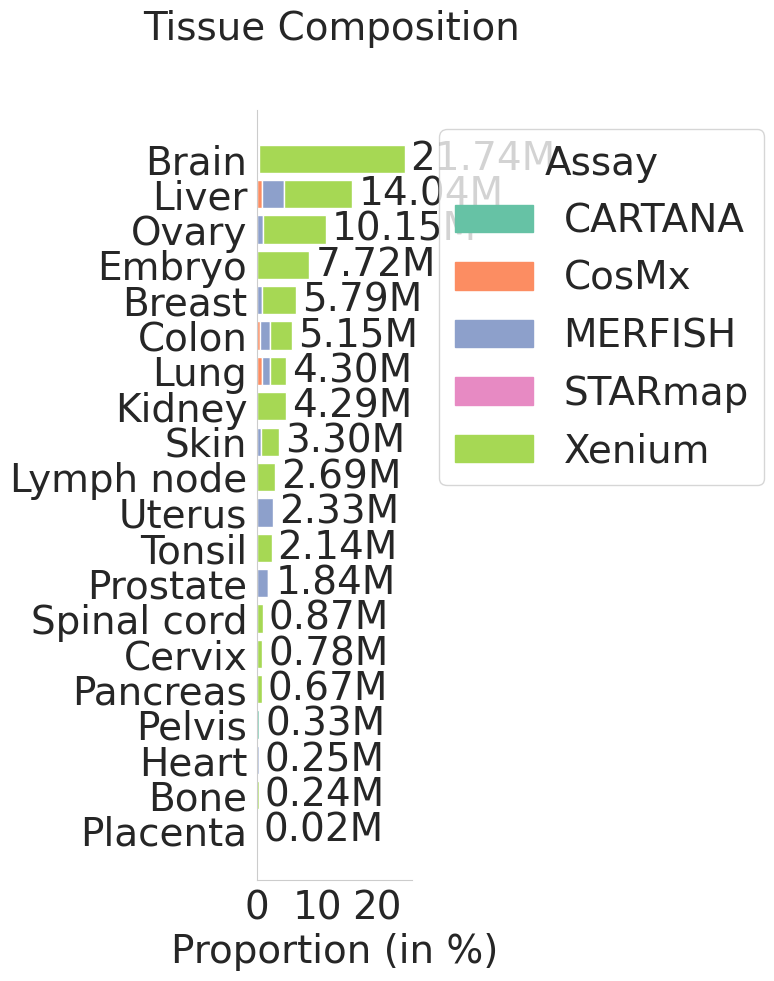

In [36]:
### Fig. 1b ###
# Tissue composition as a stacked bar chart split by assay
def tissue_distribution(num_cells, num_datasets, df, save_path, figsize, xname='percentage'):
    # ---------------- Process DataFrame ----------------
    # Create a pivot table with tissues as rows and assays as columns.
    pivot = df.groupby(['tissue', 'assay'])['Number of Cells'].sum().unstack(fill_value=0)
    # Add a column for the total cells per tissue.
    pivot['total'] = pivot.sum(axis=1)
    
    # Sort tissues by total cell count descending.
    pivot = pivot.sort_values(by='total', ascending=False)
    
    # Depending on xname, compute either percentages or use raw cell counts.
    if xname == 'percentage':
        # Convert counts to percentage of overall cells.
        pivot_perc = pivot.drop(columns='total') * 100 / num_cells
        pivot_total = pivot['total'] * 100 / num_cells
    else:  # xname == 'Number of Cells'
        pivot_perc = pivot.drop(columns='total')
        pivot_total = pivot['total']
    
    # Create pivot table of tissues.
    cleaned_tissues = pivot.index.to_series().str.capitalize()
    pivot.index = cleaned_tissues
    pivot_perc.index = cleaned_tissues
    pivot_total.index = cleaned_tissues

    # Get the list of tissues (in sorted order) and assays.
    tissues_sorted = pivot.index.tolist()
    assays = pivot_perc.columns.tolist()
    
    # Create a color palette for the assays.
    # "Set2" is a muted palette appropriate for a Nature article.
    assay_colors = dict(zip(assays, sns.color_palette("Set2", len(assays))))
    
    # ---------------- Plot Settings ----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    # fig, ax = plt.subplots(1, 1, figsize=(6, 12))
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    # ---------------- Draw Stacked Bar Chart ----------------
    # For each tissue, draw a horizontal bar split by assay contributions.
    for tissue in tissues_sorted:
        left = 0  # Starting point for the left edge of the bar segment.
        for assay in assays:
            value = pivot_perc.loc[tissue, assay]
            if value > 0:
                ax.barh(tissue, value, left=left, color=assay_colors[assay])
                left += value  # Update left position for the next segment.
    
    # Invert the y-axis so that the tissue with the most cells is on top.
    ax.invert_yaxis()
    
    # ---------------- Annotations ----------------
    # Annotate each tissue bar with its total cell count (in millions) at the end of the bar.
    for tissue in tissues_sorted:
        total_value = pivot.loc[tissue, "total"]
        ax.text(pivot_total.loc[tissue] + 1, tissue, f'{(total_value/1e6):.2f}M',
                va='center', fontsize=28)
    
    # ---------------- Labels and Axes ----------------
    if xname == 'percentage':
        xlabel = 'Proportion (in %)'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    elif xname == 'Number of Cells':
        xlabel = 'Number of Cells'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.suptitle("Tissue Composition", fontsize=28)
    
    # ---------------- Add Legend ----------------
    # Create legend handles for each assay.
    legend_handles = [mpatches.Patch(color=assay_colors[a], label=a) for a in assays]
    ax.legend(handles=legend_handles, title="Assay", bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # ---------------- Save and Visualize ----------------
    plt.savefig(save_path,
                dpi=300, bbox_inches='tight')
    plt.show()


# Example call (ensure that num_cells, num_datasets, df, data_artifacts_folder_path, and cohort_name are defined):
tissue_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
    save_path=f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_tissue_composition.svg",
    figsize=(2, 10))

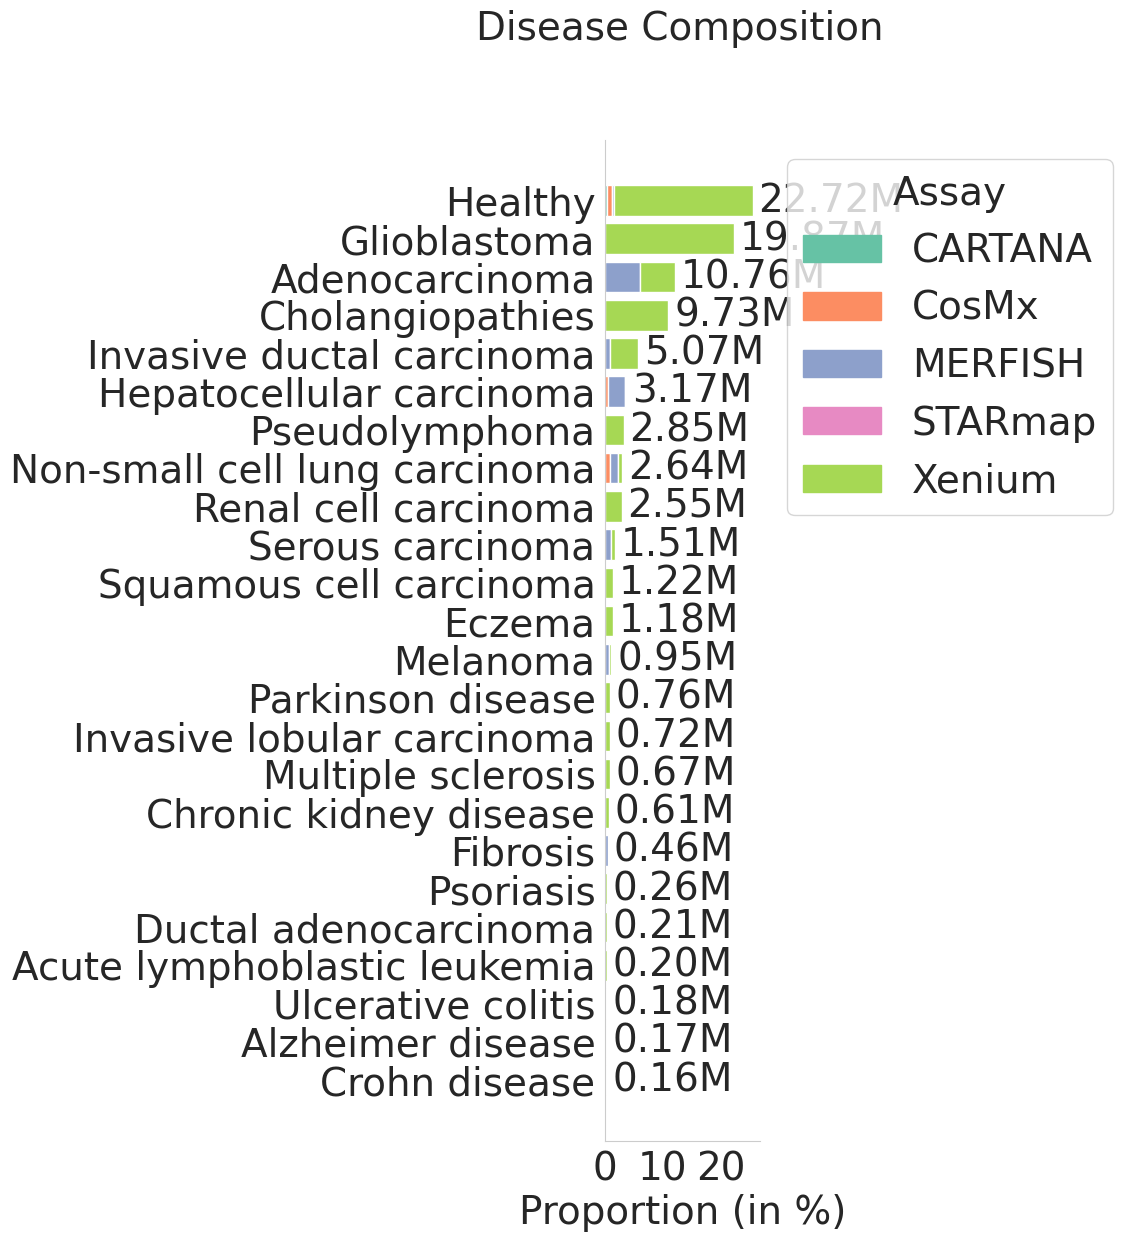

In [38]:
### Fig. 1b ###
# Tissue composition as a stacked bar chart split by assay
def condition_distribution(num_cells, num_datasets, df, save_path, figsize, xname='percentage'):
    # ---------------- Process DataFrame ----------------
    # Create a pivot table with tissues as rows and assays as columns.
    pivot = df.groupby(['condition', 'assay'])['Number of Cells'].sum().unstack(fill_value=0)
    # Add a column for the total cells per tissue.
    pivot['total'] = pivot.sum(axis=1)
    
    # Sort tissues by total cell count descending.
    pivot = pivot.sort_values(by='total', ascending=False)
    
    # Depending on xname, compute either percentages or use raw cell counts.
    if xname == 'percentage':
        # Convert counts to percentage of overall cells.
        pivot_perc = pivot.drop(columns='total') * 100 / num_cells
        pivot_total = pivot['total'] * 100 / num_cells
    else:  # xname == 'Number of Cells'
        pivot_perc = pivot.drop(columns='total')
        pivot_total = pivot['total']
    
    # Create pivot table of diseases.
    cleaned_conditions = pivot.index.to_series().str.capitalize()
    pivot.index = cleaned_conditions
    pivot_perc.index = cleaned_conditions
    pivot_total.index = cleaned_conditions

    # Get the list of tissues (in sorted order) and assays.
    conditions_sorted = pivot.index.tolist()
    assays = pivot_perc.columns.tolist()
    
    # Create a color palette for the assays.
    # "Set2" is a muted palette appropriate for a Nature article.
    assay_colors = dict(zip(assays, sns.color_palette("Set2", len(assays))))
    
    # ---------------- Plot Settings ----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    # ---------------- Draw Stacked Bar Chart ----------------
    # For each tissue, draw a horizontal bar split by assay contributions.
    for condition in conditions_sorted:
        left = 0  # Starting point for the left edge of the bar segment.
        for assay in assays:
            value = pivot_perc.loc[condition, assay]
            if value > 0:
                ax.barh(condition, value, left=left, color=assay_colors[assay])
                left += value  # Update left position for the next segment.
    
    # Invert the y-axis so that the tissue with the most cells is on top.
    ax.invert_yaxis()
    
    # ---------------- Annotations ----------------
    # Annotate each tissue bar with its total cell count (in millions) at the end of the bar.
    for condition in conditions_sorted:
        total_value = pivot.loc[condition, "total"]
        ax.text(pivot_total.loc[condition] + 1, condition, f'{(total_value/1e6):.2f}M',
                va='center', fontsize=28)
    
    # ---------------- Labels and Axes ----------------
    if xname == 'percentage':
        xlabel = 'Proportion (in %)'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    elif xname == 'Number of Cells':
        xlabel = 'Number of Cells'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.suptitle("Disease Composition", fontsize=28)
    
    # ---------------- Add Legend ----------------
    # Create legend handles for each assay.
    legend_handles = [mpatches.Patch(color=assay_colors[a], label=a) for a in assays]
    ax.legend(handles=legend_handles, title="Assay", bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # ---------------- Save and Visualize ----------------
    plt.savefig(save_path,
                dpi=300, bbox_inches='tight')
    plt.show()


# Example call (ensure that num_cells, num_datasets, df, data_artifacts_folder_path, and cohort_name are defined):
condition_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
    save_path=f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_condition_composition.svg",
    figsize=(2, 13))

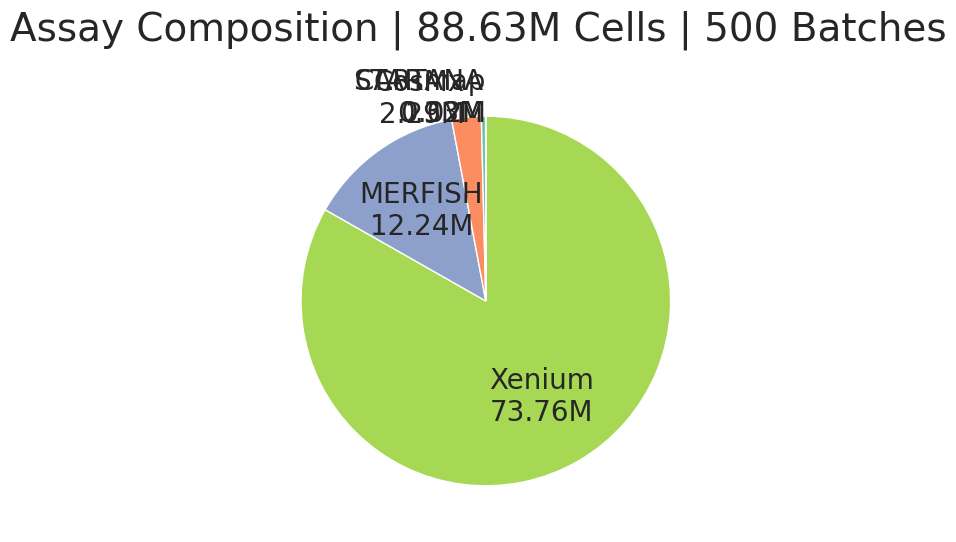

In [14]:
### Fig. 1b ###
# Assay composition as a pie chart with inline labels
def assay_distribution(num_cells, num_datasets, df, xname='percentage'):
    # ---------------- Process DataFrame ----------------
    # Aggregate cell counts by assay.
    assay_counts = df.groupby("assay")['Number of Cells'].sum().reset_index()
    # Calculate the percentage for each assay.
    assay_counts['percentage'] = (assay_counts['Number of Cells'] / num_cells) * 100
    # Sort assays by cell count descending.
    assay_counts = assay_counts.sort_values(by='Number of Cells', ascending=False)
    
    # ---------------- Fixed Color Mapping ----------------
    # Create a fixed mapping so that each assay always uses the same color.
    unique_assays = sorted(df['assay'].unique())
    assay_colors = dict(zip(unique_assays, sns.color_palette("Set2", len(unique_assays))))
    # For the assays present in assay_counts (which may be a subset), assign colors.
    colors = [assay_colors[a] for a in assay_counts['assay']]
    
    # ---------------- Plot Settings ----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    
    # ---------------- Draw Pie Chart ----------------
    # Use the specified column (usually 'percentage') for the slice sizes.
    sizes = assay_counts[xname]
    wedges, _ = ax.pie(sizes, colors=colors, startangle=90, counterclock=False)
    
    # ---------------- Place Labels ----------------
    # For each wedge, compute its mid-angle and place the label accordingly.
    for i, wedge in enumerate(wedges):
        # Calculate the mid-angle of the wedge in degrees.
        mid_angle = (wedge.theta2 + wedge.theta1) / 2.0
        # Convert the mid-angle to radians.
        rad = np.deg2rad(mid_angle)
        # Determine the (x, y) coordinates on the unit circle.
        x = np.cos(rad)
        y = np.sin(rad)
        # Get the angular span of the wedge.
        span = wedge.theta2 - wedge.theta1
        
        # Build the label (assay name and cell count in millions).
        assay_name = assay_counts.iloc[i]['assay']
        cell_label = f"{assay_counts.iloc[i]['Number of Cells'] / 1e6:.2f}M"
        label = f"{assay_name}\n{cell_label}"
        
        # Place the label inside the wedge if it is wide enough; otherwise, place it just outside.
        if span >= 40:
            r_label = 0.6  # inside the slice
            ha = 'center'
        else:
            r_label = 1.1  # outside the slice
            ha = 'left' if x > 0 else 'right'
        
        label_x = r_label * x
        label_y = r_label * y
        
        # Draw the label without any bounding box.
        ax.text(label_x, label_y, label, ha=ha, va='center', fontsize=20)
    
    # ---------------- Title and Save ----------------
    plt.suptitle(f"Assay Composition | {num_cells/1e6:.2f}M Cells | {num_batches} Batches", fontsize=28)
    plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_assay_composition.svg",
                dpi=300, bbox_inches='tight')
    plt.show()


# Example call:
# Ensure that num_cells, num_datasets, df, num_batches, and data_artifacts_folder_path are defined.
assay_distribution(num_cells, num_datasets, df, xname='percentage')

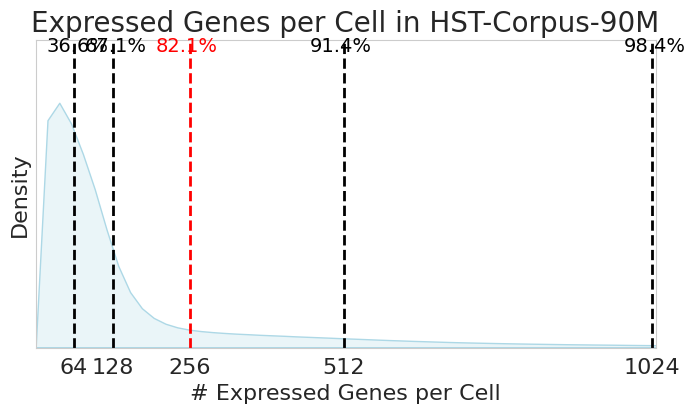

In [15]:
### Extended Data Fig. 1a ###
# Detected genes per cell in HST-Corpus
# ---------------- Flatten the List ----------------
flat_genes_per_cell = np.concatenate(genes_per_cell)

# ---------------- Create the Density Plot ----------------
plt.figure(figsize=(8, 4))
ax = sns.kdeplot(flat_genes_per_cell, bw_adjust=0.5, fill=True, color="lightblue")
plt.xlabel("# Expressed Genes per Cell", fontsize=16)
plt.ylabel("Density", fontsize=16)
plt.yticks([])  # Remove y-axis tick values
# Set x-axis ticks to only the specified values
plt.xticks([64, 128, 256, 512, 1024], fontsize=16)
plt.title("Expressed Genes per Cell in HST-Corpus-90M", fontsize=20)
# Limit the x-axis to 0–1030 so that data beyond 1030 is not displayed
plt.xlim(0, 1030)

# ---------------- Adjust Y-Axis to Make Room for Labels ----------------
current_ylim = ax.get_ylim()[1]
new_top = current_ylim * 1.2
ax.set_ylim(0, new_top)

# ---------------- Compute Percentages and Add Vertical Lines ----------------
# Define thresholds where vertical lines (and percent annotations) will be added.
thresholds = [64, 128, 256, 512, 1024]
n_total = len(flat_genes_per_cell)

# Define horizontal offsets (in data units) for the percent labels to avoid overlapping the lines.
offsets = {64: 5, 128: 5, 256: -5, 512: -5, 1024: 5}

for thresh in thresholds:
    # Compute the percentage of cells with value below the threshold.
    percent = (np.sum(flat_genes_per_cell < thresh) / n_total) * 100
    # Use red for the 256 threshold; black for the others.
    line_color = 'red' if thresh == 256 else 'black'
    plt.axvline(x=thresh, color=line_color, linestyle='--', linewidth=2)
    plt.text(thresh + offsets[thresh], new_top * 0.95, f"{percent:.1f}%",
             ha='center', va='bottom', fontsize=14, color=line_color)

# ---------------- Display and Save the Plot ----------------
plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_expressed_genes_per_cell.svg",
            dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# Keep 5k panel only
df['premium_panel'] = (df['Number of Genes'] == 4948) | (df['Number of Genes'] == 4949)
df['premium_panel'].values
genes_per_cell_premium_panel = [d for d, m in zip(genes_per_cell, df['premium_panel'].values.tolist()) if m]
print(len(genes_per_cell_premium_panel))
df_premium_panel = df[df['premium_panel']]

194


In [29]:
num_datasets_premium = df_premium_panel['dataset_id'].nunique()
print(f"Number of Datasets: {num_datasets_premium}") # 10

num_batches = len(df_premium_panel)
print(f"Number of Batches: {num_batches}") # 194

num_cells_premium = df_premium_panel['Number of Cells'].sum()
print(f"Number of Cells: {num_cells_premium}") # 26,621,953

Number of Datasets: 10
Number of Batches: 194
Number of Cells: 26621953


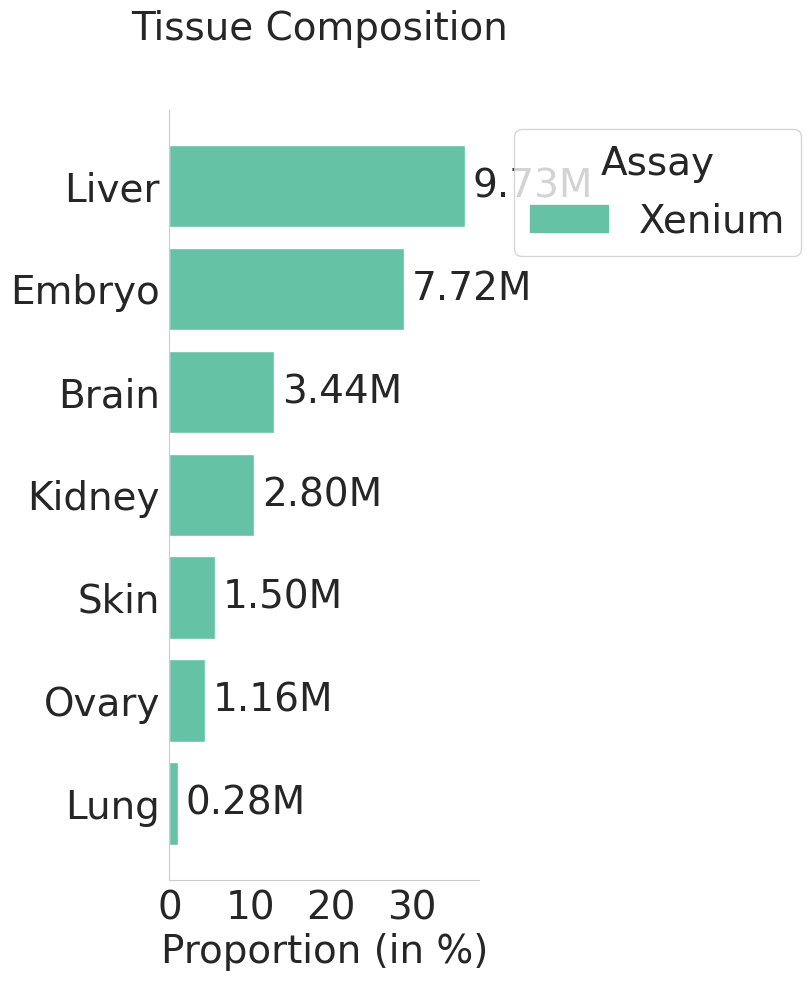

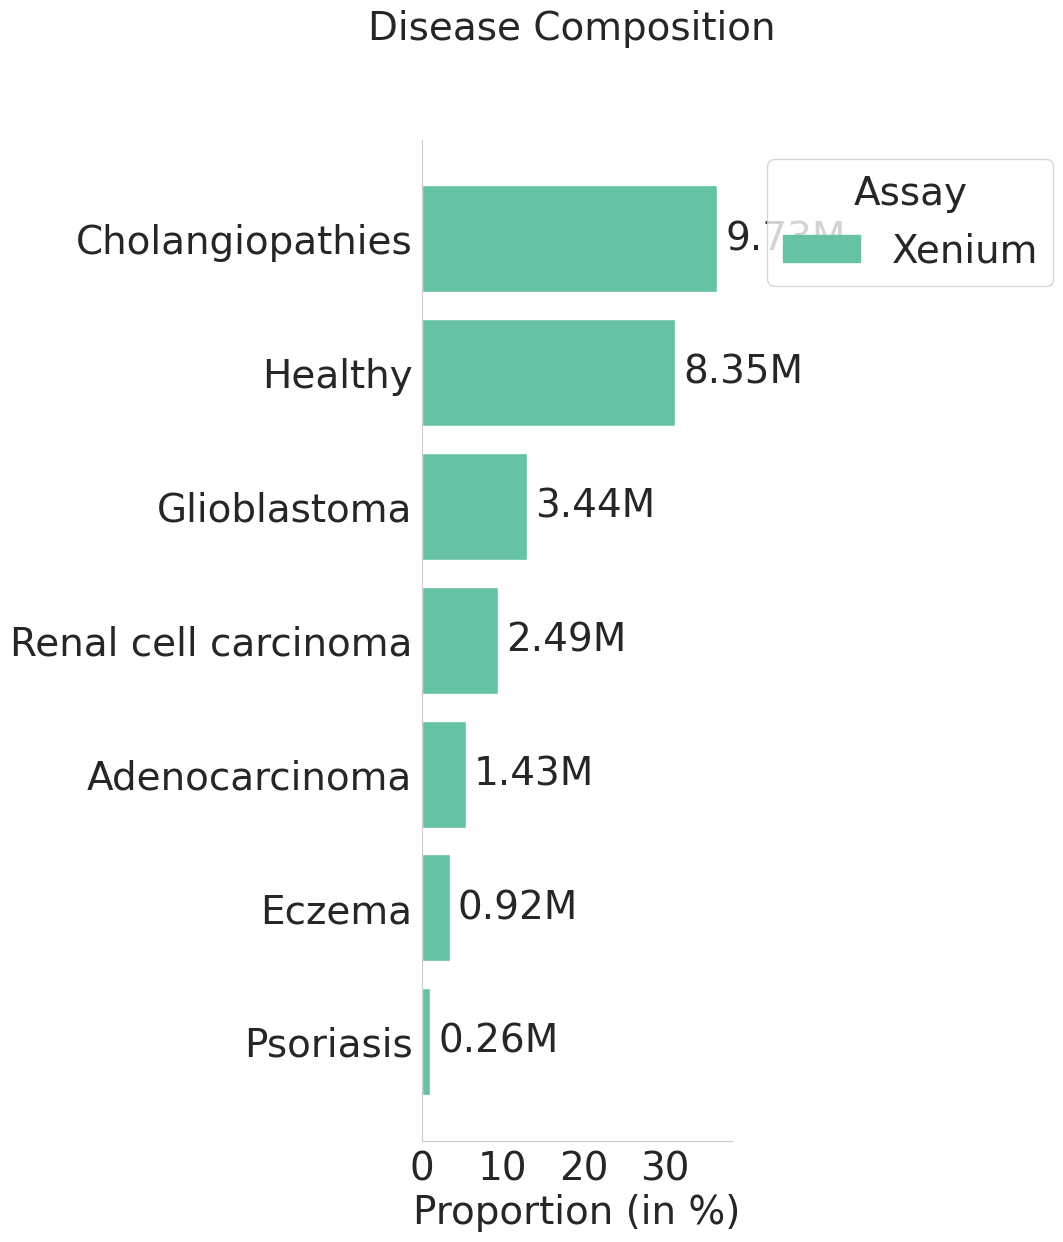

In [43]:
### Fig. x ###
tissue_distribution(
    num_cells_premium,
    num_datasets_premium,
    df_premium_panel,
    xname='percentage',
    save_path=f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_5k_panel_tissue_composition.svg",
    figsize=(4, 10))

condition_distribution(
    num_cells_premium,
    num_datasets_premium,
    df_premium_panel,
    xname='percentage',
    save_path=f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_5k_panel_condition_composition.svg",
    figsize=(4, 13))

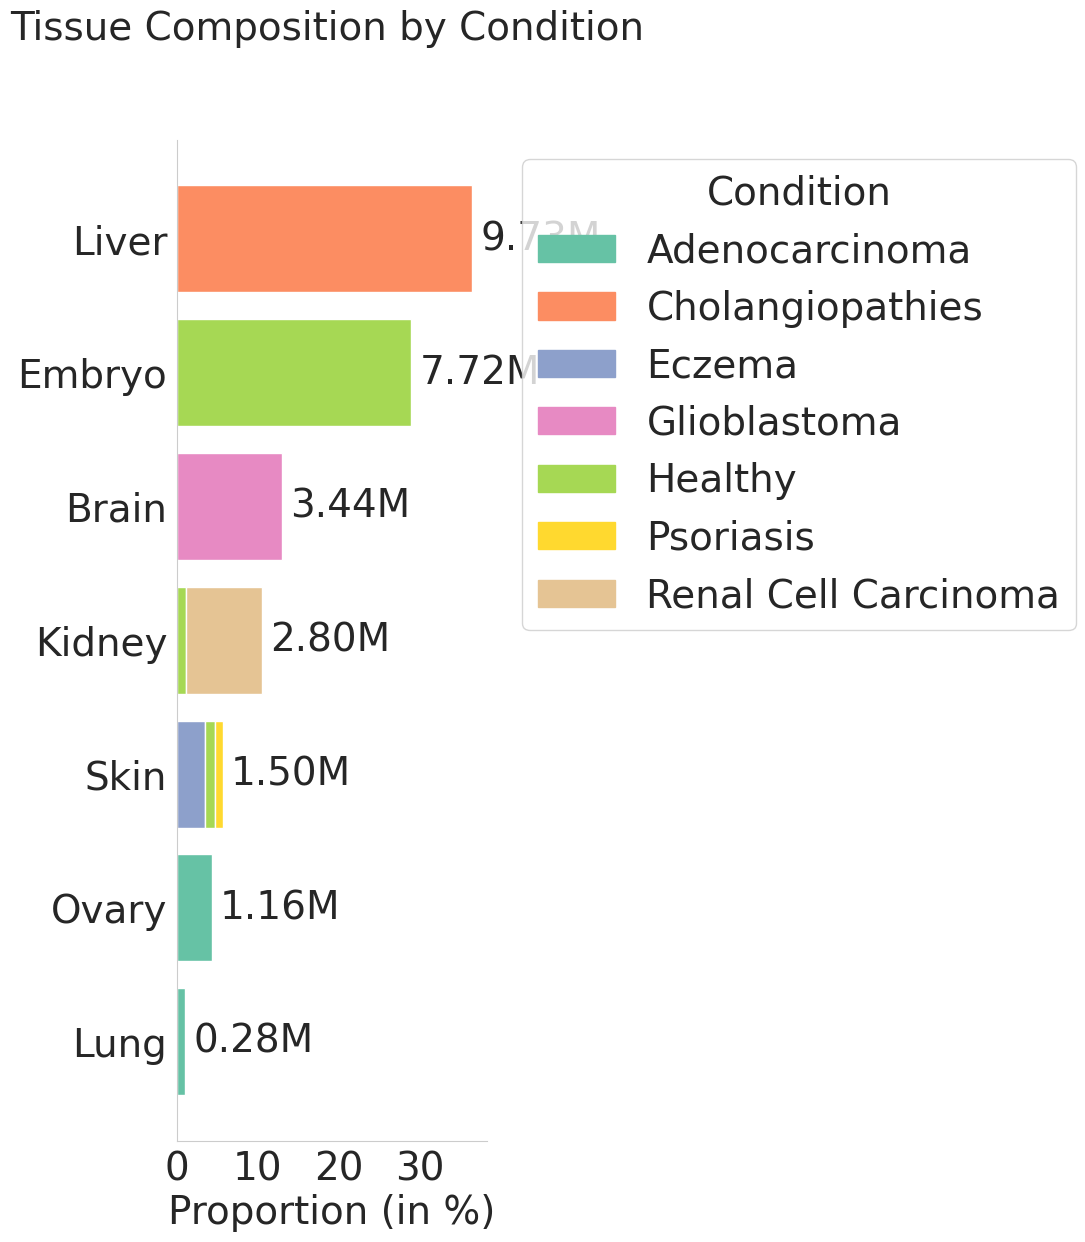

In [44]:
### Fig. x ###
def tissue_distribution_by_condition(num_cells, df, save_path, figsize, xname='percentage'):
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    import matplotlib.ticker as ticker
    import seaborn as sns

    # ---------------- Process DataFrame ----------------
    # Create a pivot table with tissues as rows and conditions as columns.
    pivot = df.groupby(['tissue', 'condition'])['Number of Cells'].sum().unstack(fill_value=0)
    pivot['total'] = pivot.sum(axis=1)

    # Sort tissues by total cell count descending.
    pivot = pivot.sort_values(by='total', ascending=False)

    # Convert counts to percentages or keep as is.
    if xname == 'percentage':
        pivot_perc = pivot.drop(columns='total') * 100 / num_cells
        pivot_total = pivot['total'] * 100 / num_cells
    else:
        pivot_perc = pivot.drop(columns='total')
        pivot_total = pivot['total']

    # Capitalize tissue names for display.
    pivot.index = pivot.index.str.capitalize()
    pivot_perc.index = pivot.index
    pivot_total.index = pivot.index

    tissues_sorted = pivot.index.tolist()
    conditions = pivot_perc.columns.tolist()

    # Create color palette.
    condition_colors = dict(zip(conditions, sns.color_palette("Set2", len(conditions))))

    # ---------------- Plot Settings ----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # ---------------- Draw Stacked Bar Chart ----------------
    for tissue in tissues_sorted:
        left = 0
        for condition in conditions:
            value = pivot_perc.loc[tissue, condition]
            if value > 0:
                ax.barh(tissue, value, left=left, color=condition_colors[condition])
                left += value

    ax.invert_yaxis()

    # ---------------- Annotations ----------------
    for tissue in tissues_sorted:
        total_value = pivot.loc[tissue, "total"]
        ax.text(pivot_total.loc[tissue] + 1, tissue, f'{(total_value/1e6):.2f}M',
                va='center', fontsize=28)

    # ---------------- Labels and Axes ----------------
    if xname == 'percentage':
        xlabel = 'Proportion (in %)'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    else:
        xlabel = 'Number of Cells'
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.suptitle("Tissue Composition by Condition", fontsize=28)

    # ---------------- Legend ----------------
    legend_handles = [mpatches.Patch(color=condition_colors[c], label=c) for c in conditions]
    ax.legend(handles=legend_handles, title="Condition", bbox_to_anchor=(1.05, 1), loc='upper left')

    # ---------------- Save and Visualize ----------------
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

tissue_distribution_by_condition(
    num_cells_premium,
    df_premium_panel,
    xname='percentage',
    save_path=f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_5k_panel_condition_by_tissue_composition.svg",
    figsize=(4, 13))

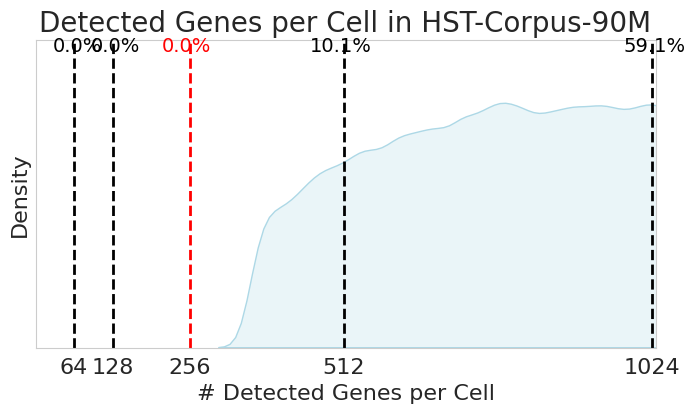

In [78]:
### Extended Data Fig. 1a ###
# Detected genes per cell in HST-Corpus
# ---------------- Flatten the List ----------------
flat_genes_per_cell_277 = np.array(genes_per_cell[277])

# ---------------- Create the Density Plot ----------------
plt.figure(figsize=(8, 4))
ax = sns.kdeplot(flat_genes_per_cell_277, bw_adjust=0.5, fill=True, color="lightblue")
plt.xlabel("# Detected Genes per Cell", fontsize=16)
plt.ylabel("Density", fontsize=16)
plt.yticks([])  # Remove y-axis tick values
# Set x-axis ticks to only the specified values
plt.xticks([64, 128, 256, 512, 1024], fontsize=16)
plt.title("Detected Genes per Cell in HST-Corpus-90M", fontsize=20)
# Limit the x-axis to 0–1030 so that data beyond 1030 is not displayed
plt.xlim(0, 1030)

# ---------------- Adjust Y-Axis to Make Room for Labels ----------------
current_ylim = ax.get_ylim()[1]
new_top = current_ylim * 1.2
ax.set_ylim(0, new_top)

# ---------------- Compute Percentages and Add Vertical Lines ----------------
# Define thresholds where vertical lines (and percent annotations) will be added.
thresholds = [64, 128, 256, 512, 1024]
n_total = len(flat_genes_per_cell_277)

# Define horizontal offsets (in data units) for the percent labels to avoid overlapping the lines.
offsets = {64: 5, 128: 5, 256: -5, 512: -5, 1024: 5}

for thresh in thresholds:
    # Compute the percentage of cells with value below the threshold.
    percent = (np.sum(flat_genes_per_cell_277 < thresh) / n_total) * 100
    # Use red for the 256 threshold; black for the others.
    line_color = 'red' if thresh == 256 else 'black'
    plt.axvline(x=thresh, color=line_color, linestyle='--', linewidth=2)
    plt.text(thresh + offsets[thresh], new_top * 0.95, f"{percent:.1f}%",
             ha='center', va='bottom', fontsize=14, color=line_color)

# ---------------- Display and Save the Plot ----------------
plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_detected_genes_per_cell_277.svg",
            dpi=300, bbox_inches='tight')
plt.show()

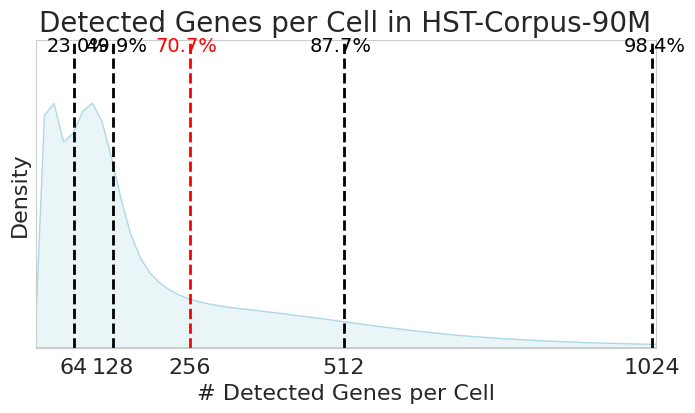

In [64]:
### Extended Data Fig. 1a ###
# Detected genes per cell in HST-Corpus
# ---------------- Flatten the List ----------------
flat_genes_per_cell_large_panel = np.concatenate(genes_per_cell_large_panel)

# ---------------- Create the Density Plot ----------------
plt.figure(figsize=(8, 4))
ax = sns.kdeplot(flat_genes_per_cell_large_panel, bw_adjust=0.5, fill=True, color="lightblue")
plt.xlabel("# Detected Genes per Cell", fontsize=16)
plt.ylabel("Density", fontsize=16)
plt.yticks([])  # Remove y-axis tick values
# Set x-axis ticks to only the specified values
plt.xticks([64, 128, 256, 512, 1024], fontsize=16)
plt.title("Detected Genes per Cell in HST-Corpus-90M", fontsize=20)
# Limit the x-axis to 0–1030 so that data beyond 1030 is not displayed
plt.xlim(0, 1030)

# ---------------- Adjust Y-Axis to Make Room for Labels ----------------
current_ylim = ax.get_ylim()[1]
new_top = current_ylim * 1.2
ax.set_ylim(0, new_top)

# ---------------- Compute Percentages and Add Vertical Lines ----------------
# Define thresholds where vertical lines (and percent annotations) will be added.
thresholds = [64, 128, 256, 512, 1024]
n_total = len(flat_genes_per_cell_large_panel)

# Define horizontal offsets (in data units) for the percent labels to avoid overlapping the lines.
offsets = {64: 5, 128: 5, 256: -5, 512: -5, 1024: 5}

for thresh in thresholds:
    # Compute the percentage of cells with value below the threshold.
    percent = (np.sum(flat_genes_per_cell_large_panel < thresh) / n_total) * 100
    # Use red for the 256 threshold; black for the others.
    line_color = 'red' if thresh == 256 else 'black'
    plt.axvline(x=thresh, color=line_color, linestyle='--', linewidth=2)
    plt.text(thresh + offsets[thresh], new_top * 0.95, f"{percent:.1f}%",
             ha='center', va='bottom', fontsize=14, color=line_color)

# ---------------- Display and Save the Plot ----------------
plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_detected_genes_per_cell_large_panel.svg",
            dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
### Extended Data Fig. 1b ###
# Number of cells per number of genes

# -----------------------------
# Data Preparation
# -----------------------------
# Compute the total number of cells for each tissue category
tissue_totals = df.groupby("tissue")["Number of Cells"].sum()

# Identify tissues with a total cell count >= 2 million
tissues_to_keep = tissue_totals[tissue_totals >= 2e6].index.tolist()

# Create a new column grouping tissues; those not meeting the threshold become "Other"
df["tissue_grouped"] = df["tissue"].apply(lambda x: x if x in tissues_to_keep else "Other")

# Determine the ordering for tissues (hue) and assays (style) by total number of cells (descending)
tissue_order = (df.groupby("tissue_grouped")["Number of Cells"]
                  .sum()
                  .sort_values(ascending=False)
                  .index
                  .tolist())
assay_order = (df.groupby("assay")["Number of Cells"]
                 .sum()
                 .sort_values(ascending=False)
                 .index
                 .tolist())

# Define a color palette for tissues using "tab20" and a marker mapping for assays
palette = dict(zip(tissue_order, sns.color_palette("tab20", n_colors=len(tissue_order))))
markers_list = ['o', 's', 'D', '^', 'v', 'P', '*', 'X']  # Extend this list if needed
marker_map = dict(zip(assay_order, markers_list[:len(assay_order)]))

# -----------------------------
# Plotting with Broken Axes
# -----------------------------
sns.set(style="whitegrid", context="talk", rc={"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 20})
plt.rcParams.update({'font.size': 20})

# Create a figure with increased width
fig = plt.figure(figsize=(9, 7))

# Define the broken x-axis segments:
bax = brokenaxes(xlims=((0, 1100), (4500, 5200), (5900, 6100), (18800, 19000)), hspace=.05, d=0.01, fig=fig)

# Plot each point (by tissue and assay) into the appropriate x-axis segment
for tissue in tissue_order:
    for assay in assay_order:
        subset = df[(df["tissue_grouped"] == tissue) & (df["assay"] == assay)]
        if not subset.empty:
            bax.scatter(
                subset["Number of Genes"],
                subset["Number of Cells"],
                color=palette[tissue],
                marker=marker_map[assay],
                s=30,      # Dot size reduced to 30
                alpha=0.6
            )

# Format y-axis ticks (display in millions) and set x-axis ticks every 600 units for each segment
for ax in bax.axs:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M'))
    ax.xaxis.set_major_locator(MultipleLocator(300))

# Adjust overall figure margins to create extra space at the bottom and right for labels and legends.
bax.fig.subplots_adjust(right=0.8, top=0.85, bottom=0.2)

# Set common x and y labels with increased label padding to avoid overlapping tick labels.
bax.set_xlabel("Number of Probed Genes", labelpad=20)
bax.set_ylabel("Number of Cells", labelpad=20)
plt.suptitle("Sample Statistics", y=0.98)

# -----------------------------
# Create Custom Legends
# -----------------------------
# Legend for tissue groups (colors)
tissue_handles = [mpatches.Patch(color=palette[tissue], label=tissue) for tissue in tissue_order]

# Legend for assays (markers)
assay_handles = [
    mlines.Line2D([], [], color='black', marker=marker_map[assay],
                  linestyle='None', markersize=10, label=assay)
    for assay in assay_order
]

# Place the legends outside the plot area on the right.
leg1 = bax.fig.legend(handles=tissue_handles, title="Tissue Grouped",
                      loc='upper left', bbox_to_anchor=(0.82, 0.85))
leg2 = bax.fig.legend(handles=assay_handles, title="Assay",
                      loc='lower left', bbox_to_anchor=(0.82, 0.4))

# Display and save plot
plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_n_cells_by_n_genes.svg",
            dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
### Not used ###
def plot_box_with_dots(df):
    """
    Creates a boxplot with overlaid dots for the "Number of Cells" per "assay".
    - Box colors are set to grey.
    - Overlay dots are set to black.
    - Font sizes are increased for better readability.
    - Y-axis labels are formatted to show millions (e.g., "2.5M" instead of "2.5e6").
    - Title is set to "Number of Cells per Batch".
    """
    
    # 1) Increase the overall font size and set font family
    plt.rcParams.update({
        'font.size': 16,        # Global font size
        'font.family': 'sans-serif',
    })

    # 2) Create the plot
    fig, ax = plt.subplots(figsize=(7, 5))

    # 3) Boxplot with narrower boxes and grey colors
    sns.boxplot(
        data=df,
        x="assay",
        y="Number of Cells",
        showfliers=False,   # Hide outlier points to reduce clutter
        width=0.4,          # Narrower boxes
        ax=ax,
        boxprops={
            'facecolor': 'lightgrey',  # Light grey fill
            'edgecolor': 'grey'        # Grey edges
        },
        medianprops={
            'color': 'black'           # Black median line
        },
        whiskerprops={
            'color': 'grey'            # Grey whiskers
        },
        capprops={
            'color': 'grey'            # Grey caps
        }
    )

    # 4) Overlay the dots (black)
    sns.stripplot(
        data=df,
        x="assay",
        y="Number of Cells",
        color="black",      # Black dots
        alpha=0.7,          # Slight transparency
        size=4,             # Dot size
        jitter=True,        # Spread out points horizontally
        ax=ax
    )

    # 5) Format y-axis to show millions (e.g., "2.5M" instead of "2.5e6")
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M")
    )

    # 6) Change axis labels
    ax.set_ylabel("Number of Cells", fontsize=18)
    ax.set_xlabel("Assay", fontsize=18)

    # 7) Add title
    ax.set_title("Number of Cells per Batch", fontsize=18)

    # 8) Add vertical gridlines for better readability
    ax.grid(
        axis='x',
        which='major',
        linestyle='--',  # Dash pattern: 5 points on, 10 points off
        color='grey',
        alpha=0.5
    )

    # 9) Adjust layout to prevent clipping of labels and title
    plt.tight_layout()

    # 10) Save the figure (optional)
    # plt.savefig("assay_distribution_boxplot.svg", dpi=300, bbox_inches='tight')

    # 11) Display the plot
    plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_cells_per_batch.svg", dpi=300, bbox_inches='tight')
    plt.show()

# Usage:
plot_box_with_dots(df)

In [ ]:
### Not used ###
def jointplot_linear_regression_dual_zoomed(df):
    """
    Creates a figure with two subplots:
    - Left: Full dataset with per-assay and global linear regression lines.
    - Right: Subset (Number of Genes < 1000) with per-assay regression lines
             and the global regression line from the full dataset (clipped to x < 1000).
             
    Each subplot has its own y-axis, providing a true zoom-in effect for the subset.
    Font sizes are increased for better readability, and the "Global Fit" label is removed from the legends.
    
    Parameters:
    - df (pd.DataFrame): DataFrame containing the data with columns "assay", "Number of Genes", and "Median Counts Per Cell".
    """
    df = df[df['Number of Genes'] < 18000]
    
    # 1. Increase global font size & set font family
    plt.rcParams.update({
        'font.size': 36,            # Increased global font size
        'font.family': 'sans-serif',
    })
    
    point_size = 150  # Larger scatter markers for better visibility
    
    # 2. Create a figure with two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(30, 12), sharey=False)
    
    # Define colors for assays
    unique_assays = df["assay"].unique()
    colors = sns.color_palette(n_colors=len(unique_assays))
    assay_color_map = {assay: colors[i] for i, assay in enumerate(unique_assays)}
    
    # -------------- Helper Function --------------
    def fit_linear_regression(x, y):
        """
        Fits a linear regression: y = intercept + slope * x
        Returns slope, intercept, and r_value.
        """
        valid_mask = ~np.isnan(x) & ~np.isnan(y)
        x_valid = x[valid_mask]
        y_valid = y[valid_mask]
        
        if len(x_valid) < 2:
            return None, None, None  # Not enough data to fit
        
        slope, intercept, r_val, p_val, std_err = linregress(x_valid, y_valid)
        
        return slope, intercept, r_val
    
    # -------------- Plot 1: Full Dataset --------------
    ax1 = axes[0]
    
    # Scatter plot
    sns.scatterplot(
        data=df,
        x="Number of Genes",
        y="Median Counts Per Cell",
        hue="assay",
        palette=assay_color_map,
        s=point_size,
        alpha=0.7,
        edgecolor='white',
        ax=ax1
    )
    
    # Fit and plot global regression line (without label)
    slope_g, intercept_g, r_val_g = fit_linear_regression(df["Number of Genes"].values, df["Median Counts Per Cell"].values)
    if slope_g is not None:
        x_vals_global = np.linspace(df["Number of Genes"].min(), df["Number of Genes"].max(), 200)
        y_vals_global = intercept_g + slope_g * x_vals_global
        ax1.plot(x_vals_global, y_vals_global, color='black', lw=3, label=None)  # label=None removes it from legend
        
        # Annotate global fit
        idx_annot = int(0.9 * len(x_vals_global))
        x_text = x_vals_global[idx_annot]
        y_text = y_vals_global[idx_annot]
        x_range = df["Number of Genes"].max() - df["Number of Genes"].min()
        x_text -= 0.45 * x_range
        print(slope_g)
        print(intercept_g)
        eq_text = f"Linear Fit:\ny = {slope_g:.2f} x + {intercept_g:.2f}"
        ax1.text(
            x_text,
            y_text,
            eq_text,
            color="black",
            ha="left",
            va="bottom"
        )
    
    # Legend (only assays, no 'Global Fit')
    handles, labels = ax1.get_legend_handles_labels()
    # Remove 'Global Fit' if it was accidentally included
    handles_labels = dict(zip(labels, handles))
    if 'Global Fit' in handles_labels:
        del handles_labels['Global Fit']
    ax1.legend(
        handles=handles_labels.values(),
        labels=handles_labels.keys(),
        title="Assay",
        loc='lower right',
        markerscale=2,
        handletextpad=0.5
    )
    
    # Title
    ax1.set_title("Counts per Probed Genes (All Batches)")
    
    # -------------- Plot 2: Subset Data (Number of Genes < 1000) --------------
    ax2 = axes[1]
    
    # Subset data
    subset_df = df[df["Number of Genes"] < 1000]
    
    # Scatter plot without legend
    sns.scatterplot(
        data=subset_df,
        x="Number of Genes",
        y="Median Counts Per Cell",
        hue="assay",
        palette=assay_color_map,
        s=point_size,
        alpha=0.7,
        edgecolor='white',
        ax=ax2,
        legend=False  # Disable legend for the second subplot
    )
    
    # Fit and plot global regression line (clipped to x < 1000)
    if slope_g is not None:
        x_vals_global_subset = np.linspace(df["Number of Genes"].min(), 1000, 200)
        y_vals_global_subset = intercept_g + slope_g * x_vals_global_subset
        ax2.plot(x_vals_global_subset, y_vals_global_subset, color='black', lw=3, label=None)  # label=None removes it from legend
    
    # Remove legend from the second subplot entirely
    # (Already disabled via `legend=False`, but ensuring no legend exists)
    if ax2.get_legend() is not None:
        ax2.get_legend().remove()
    
    # Title
    ax2.set_title("Counts per Probed Genes (Batches < 1000 Genes)")
    
    # -------------- Common Settings --------------
    
    # Format y-axis to show raw counts (no scaling)
    for ax in axes:
        ax.yaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, pos: f"{int(x)}")
        )
        ax.set_xlabel("Number of Probed Genes")
        ax.set_ylabel("Median Counts Per Cell")
    
    # Overall Figure Title
    fig.suptitle("Batch Statistics", y=1.05)
    
    # Adjust layout to prevent overlapping
    plt.tight_layout(rect=[0, 0, 1, 1])
    
    # -------------- Add Gridlines (Optional) --------------
    for ax in axes:
        ax.grid(
            axis='x',
            which='major',
            linestyle='--',  # Dash pattern: 5 points on, 10 points off
            color='grey',
            alpha=0.5
        )
    
    # -------------- Save and Show --------------
    # Uncomment the following line to save the figure
    plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_counts_per_probed_genes.svg", dpi=300, bbox_inches='tight')
    
    plt.show()

# **Usage:**
jointplot_linear_regression_dual_zoomed(df)

### import matplotlib.ticker as ticker

def jointplot(df):
    # Increase the global font size and set font family
    plt.rcParams.update({
        'font.size': 16,
        'font.family': 'sans-serif',
    })

    point_size = 30  # Larger scatter markers
    
    g = sns.jointplot(
        data=df,
        x="Number of Genes",
        y="Number of Cells",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},  # larger markers
        marginal_kws={"cut": 0}
    )

    # Force axes to start at 0 (optional)
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # --- Formatter for millions ---
    def millions_formatter(x, pos):
        return f"{x/1e6:.2f}M"

    # Apply the formatter on the X axis and Y axis
    g.ax_joint.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

    # Optionally rename the axes labels to reflect the new units (Millions)
    g.ax_joint.set_xlabel("Number of Genes")
    g.ax_joint.set_ylabel("Number of Cells (M)")

    # Legend: only scatter (assay categories), bigger markers in legend
    g.ax_joint.legend(
        title="Assay", 
        loc="upper right", 
        markerscale=1.3, 
        handletextpad=0.
    )

    # Save figure
    plt.savefig(f"{data_artifacts_folder_path}/{cohort_name}/{cohort_name}_batchstatistics2.svg", dpi=300, bbox_inches='tight')
    plt.show()

# Usage:
jointplot(df)